Loaded 186 triplets
Using corpus size: 2229
Selected 1 anchors
Skip Fine-tuned Qwen2.5 LoRA: directory not found at /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/../checkpoints/qwen_2.5_wikidata

Anchor 1 directory: /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1
Saved anchor text to: /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1/selected_anchor.txt
Building plot for TF-IDF (anchor 1) ...


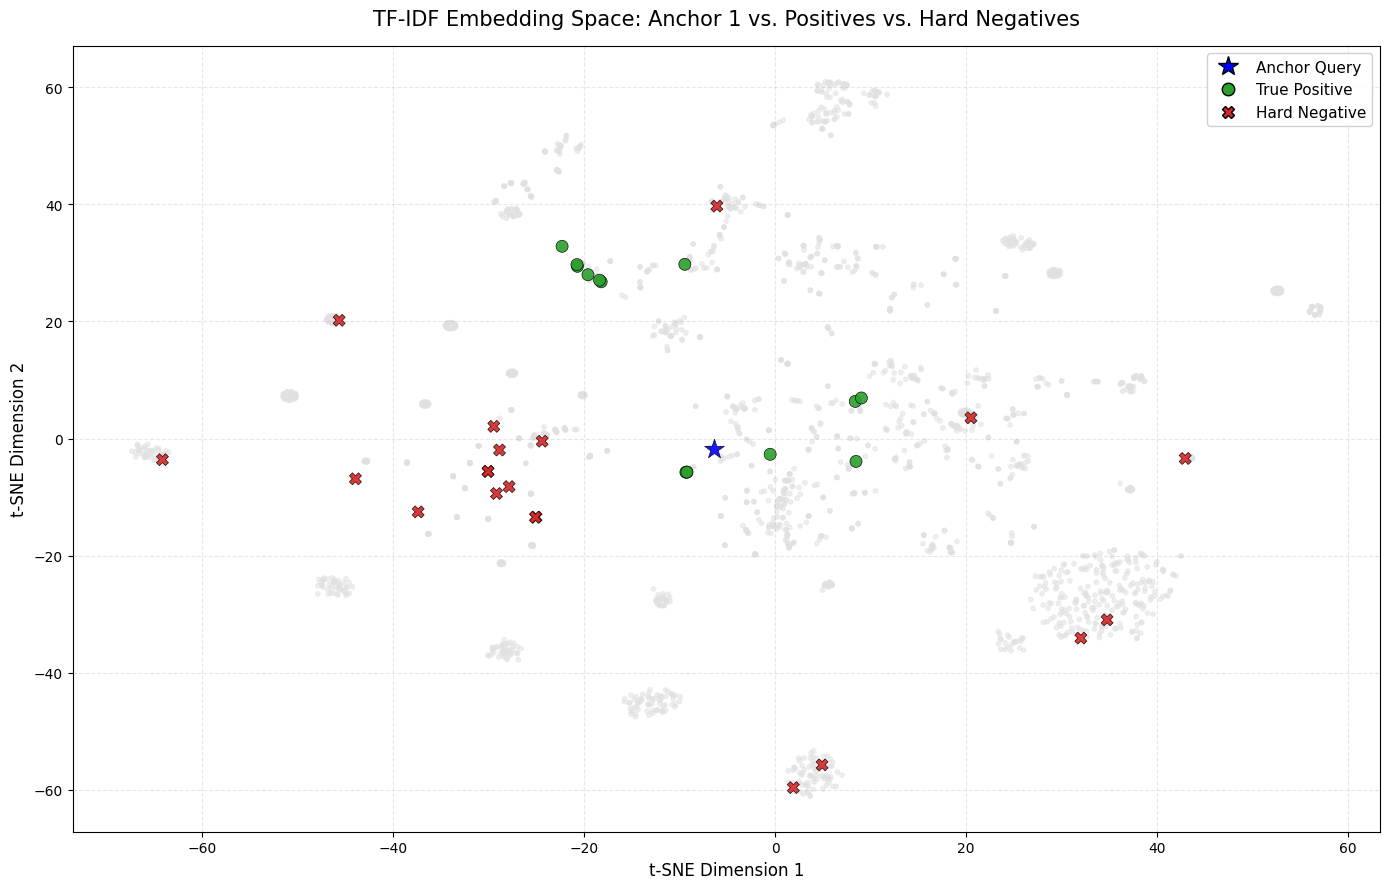

Saved /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1/tf_idf.png
Building plot for Qwen3-Embedding (anchor 1) ...


Loading weights: 100%|██████████| 310/310 [00:00<00:00, 10219.40it/s]


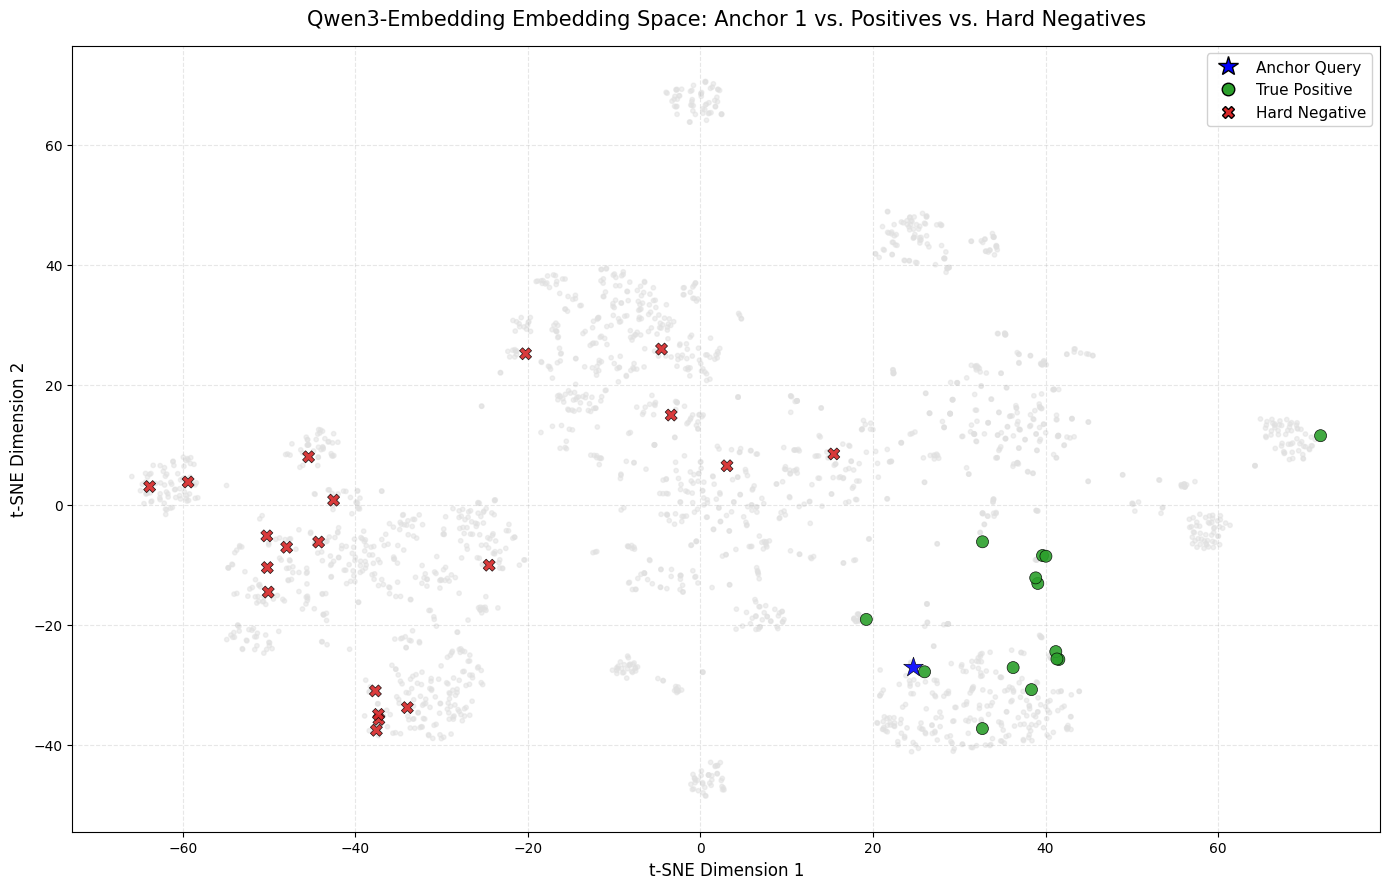

Saved /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1/qwen3_embedding.png
Building plot for MiniLM (anchor 1) ...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4465.02it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


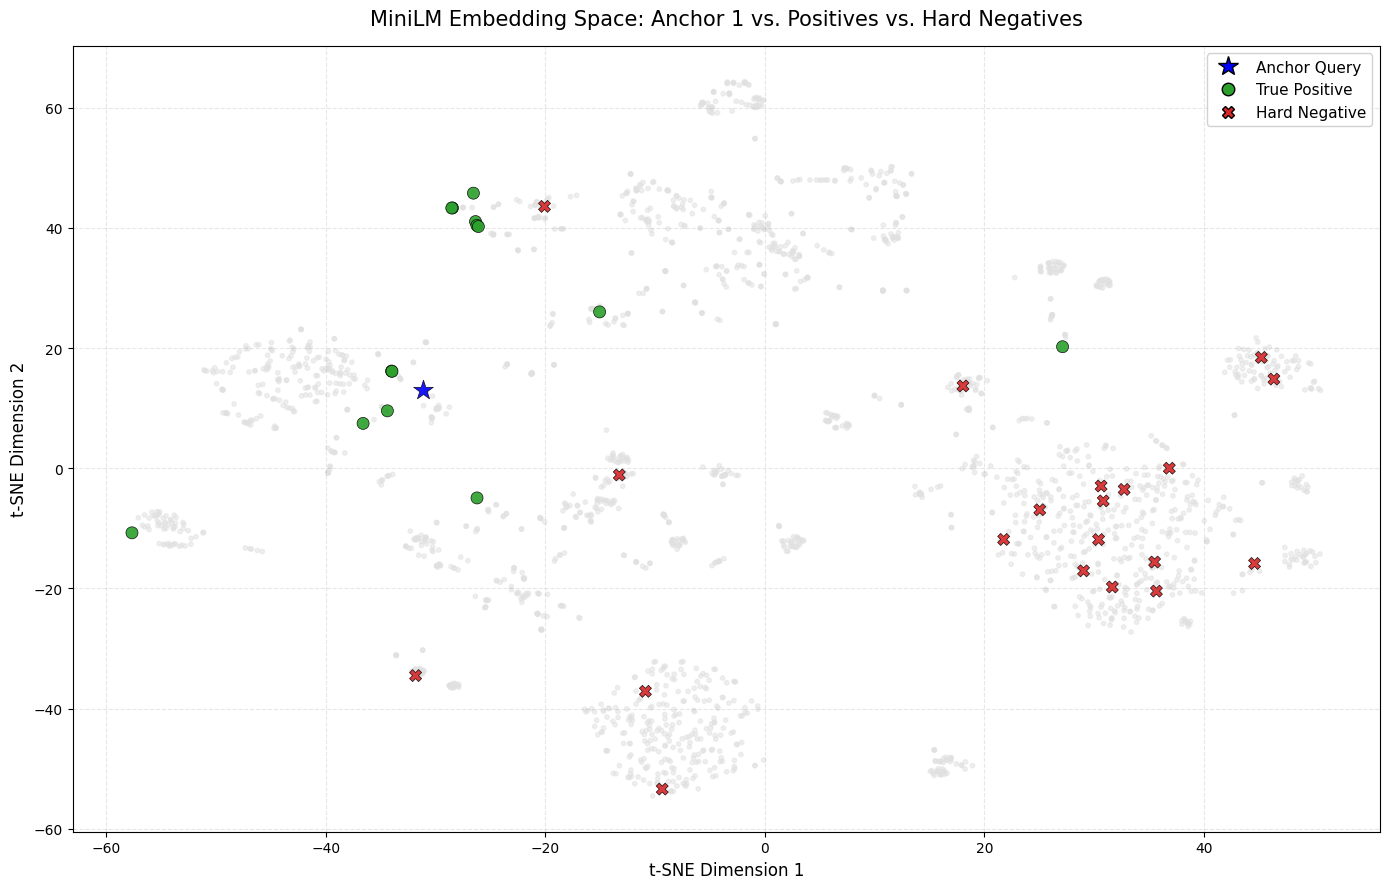

Saved /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1/minilm.png
Building plot for E5 (anchor 1) ...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5901.46it/s]
BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


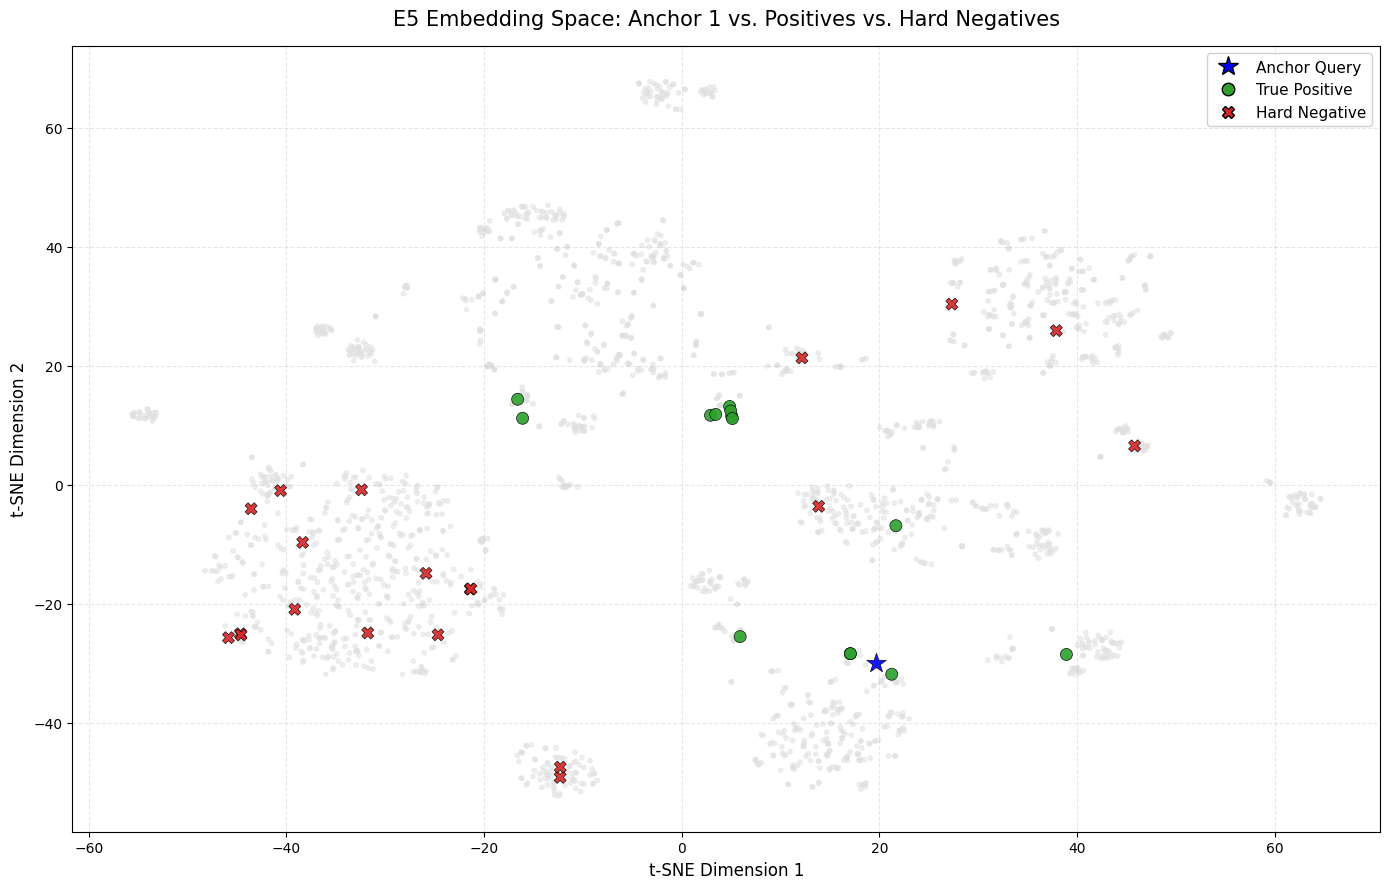

Saved /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1/e5.png
Building plot for MPNet (anchor 1) ...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4576.05it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


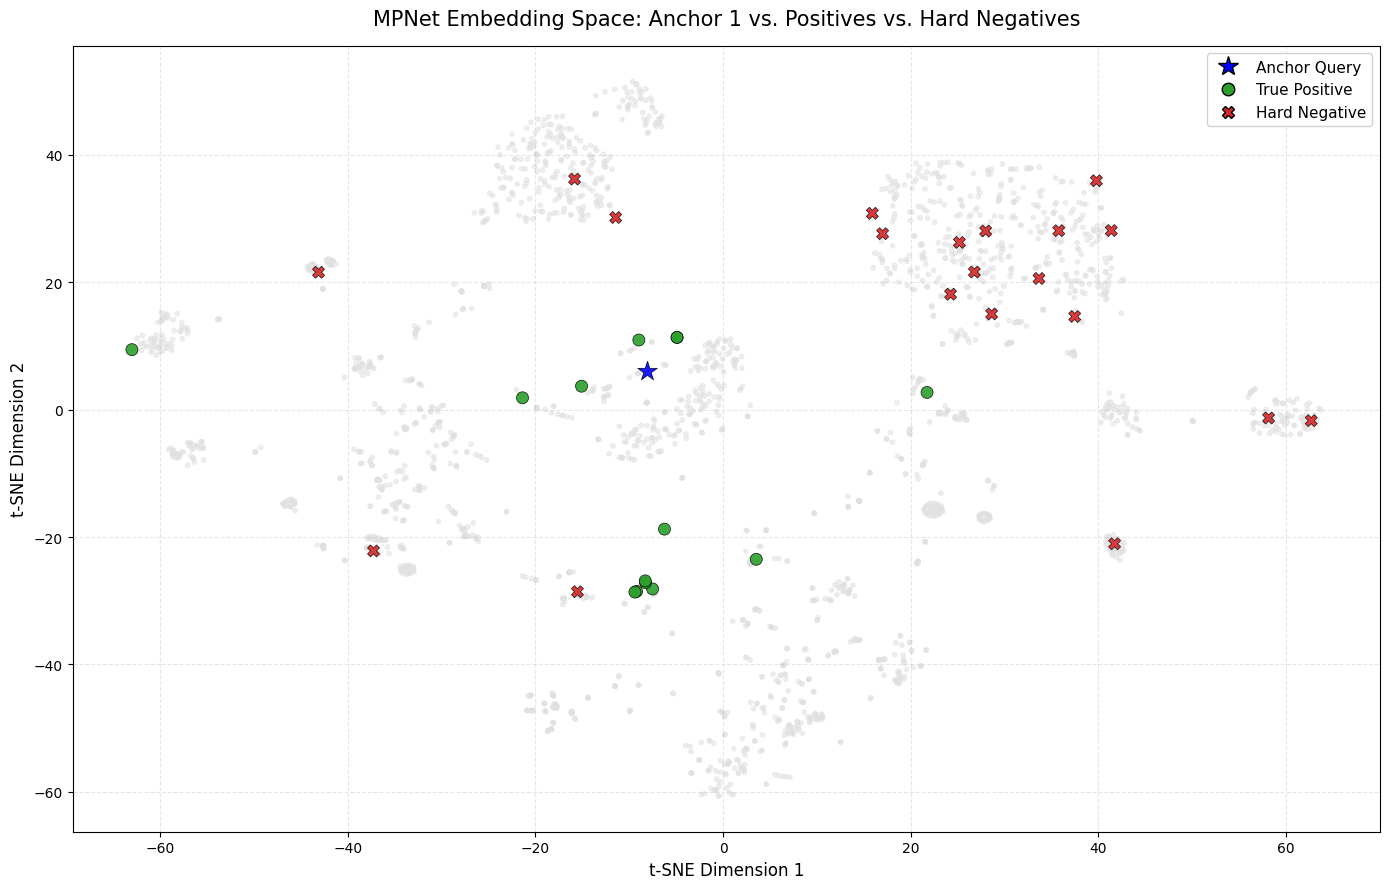

Saved /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1/mpnet.png
Building plot for SPARQLCE (anchor 1) ...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 34471.83it/s]


Loading model from /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/../checkpoints/wikidata_model_semantic-20.pt...


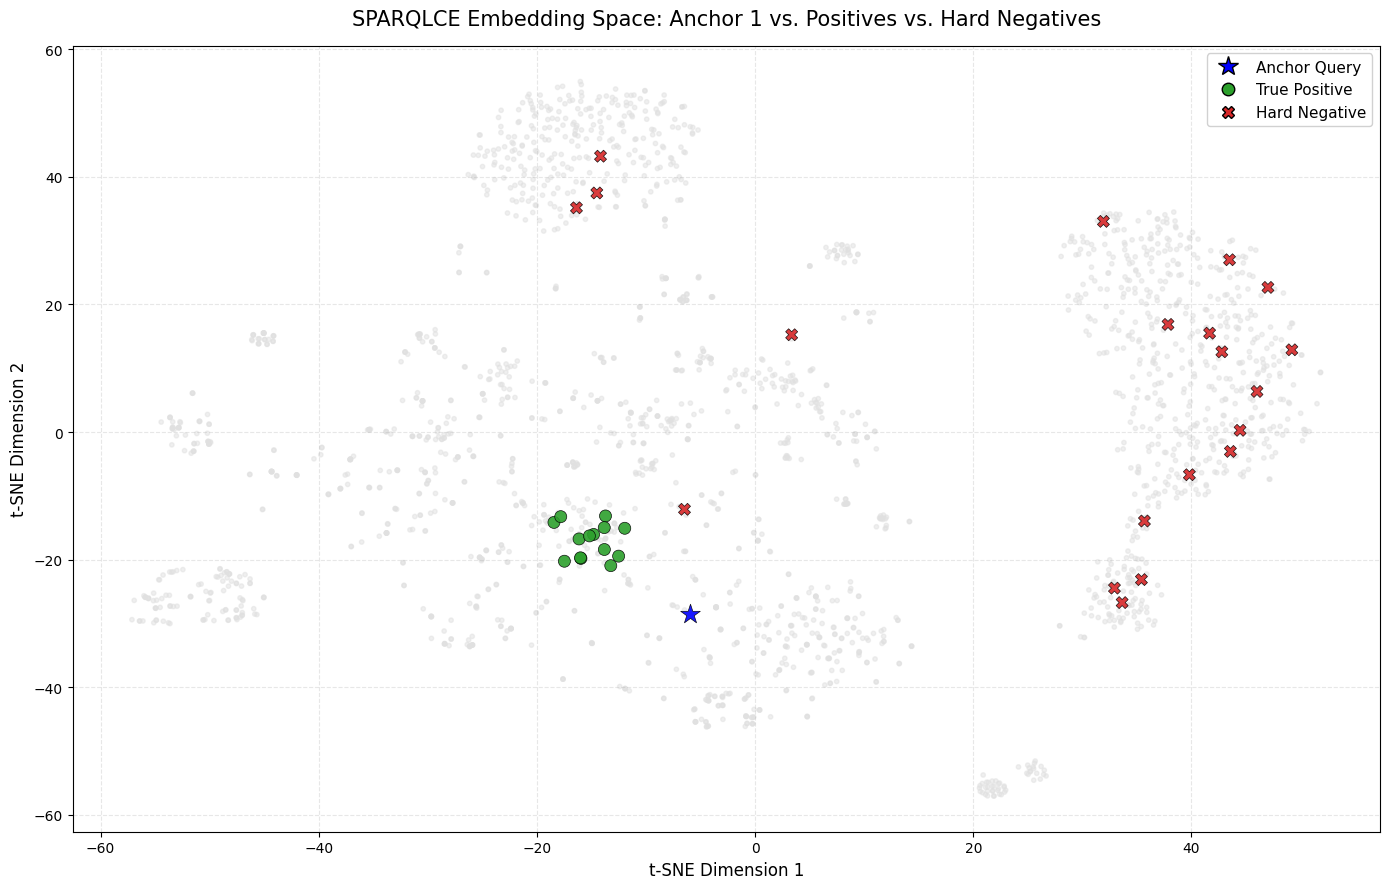

Saved /local/upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/visualization/images/wikidata/wikidata_anchor_1_s2_run_1/sparqlce.png


In [3]:
import os
import sys

from datetime import datetime
from pathlib import Path
from typing import List, Callable

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.lines import Line2D
from peft import PeftConfig, PeftModel
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize as sk_normalize
from tqdm import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
from src.embedder import SPARQLEmbedder

PROJECT_ROOT = os.path.abspath("../evaluation")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
from utils import build_emb_map_sentence_transformer, build_emb_map_sparqlce, build_global_corpus, load_triplets

# ============================================================
# CONFIG
# ============================================================

PROJECT_ROOT = Path.cwd()

DATA_PATH = PROJECT_ROOT / "../evaluation/dataset" / "hard_triplets_tfidf_wikidata.json"
SPARQLCE_CHECKPOINT = PROJECT_ROOT / "../checkpoints" / "wikidata_model_semantic-20.pt"
QWEN_LORA_PATH = PROJECT_ROOT / "../checkpoints" / "qwen_2.5_wikidata"
OUTPUT_ROOT = PROJECT_ROOT / "images" / "wikidata"

QWEN_EMBED_MODEL_NAME = "Qwen/Qwen3-Embedding-0.6B"
MINILM_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
E5_MODEL_NAME = "intfloat/e5-base-v2"
MPNET_MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"

NUM_ANCHORS = 1
ANCHOR_SELECTION = "random"  # "top_positive_count" or "random"
SAMPLE_SIZE = 0  # 0 = use all queries
BATCH_SIZE = 32
QWEN_FT_BATCH_SIZE = 8
QWEN_FT_MAX_LENGTH = 768
TFIDF_MAX_FEATURES = 5000
SVD_DIM = 50
SEED = 2
DPI = 300

# ============================================================
# HELPERS
# ============================================================

def set_seed(seed: int) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def get_query_text(x) -> str:
    if x is None:
        return ""
    if isinstance(x, dict):
        return str(x.get("query") or x.get("sparql") or "").strip()
    return str(x).strip()

def format_sparql_to_text_prompt(sparql: str) -> str:
    return (
        "You are an expert in knowledge graphs.\n\n"
        "### Instruction\n"
        "Convert the SPARQL query into a clear natural language question.\n\n"
        f"### SPARQL Query\n{sparql}\n\n"
        "### Natural Text\n"
    )

def l2_normalize(x: torch.Tensor, eps: float = 1e-12) -> torch.Tensor:
    return x / x.norm(dim=-1, keepdim=True).clamp(min=eps)

class QwenSPARQLEncoder:
    def __init__(self, lora_path: str, device: str | None = None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

        peft_cfg = PeftConfig.from_pretrained(lora_path)
        self.base_model_name = peft_cfg.base_model_name_or_path

        try:
            self.tokenizer = AutoTokenizer.from_pretrained(lora_path)
        except Exception:
            self.tokenizer = AutoTokenizer.from_pretrained(self.base_model_name)

        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token

        if self.device == "cuda":
            bnb_config = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_use_double_quant=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.float16,
            )
            try:
                base_model = AutoModelForCausalLM.from_pretrained(
                    self.base_model_name,
                    quantization_config=bnb_config,
                    device_map={"": torch.cuda.current_device()},
                )
            except torch.cuda.OutOfMemoryError:
                base_model = AutoModelForCausalLM.from_pretrained(
                    self.base_model_name,
                    quantization_config=bnb_config,
                    device_map="auto",
                    llm_int8_enable_fp32_cpu_offload=True,
                )
        else:
            base_model = AutoModelForCausalLM.from_pretrained(
                self.base_model_name,
                torch_dtype=torch.float32,
            ).to(self.device)

        self.model = PeftModel.from_pretrained(base_model, lora_path, is_trainable=False)
        self.model.eval()

    @torch.no_grad()
    def encode_sparql(self, sparql_list: List[str], batch_size: int = 8, max_length: int = 768) -> np.ndarray:
        all_embeddings = []
        model_device = next(self.model.parameters()).device

        for start in tqdm(range(0, len(sparql_list), batch_size), desc="Encoding Qwen LoRA"):
            batch = sparql_list[start:start + batch_size]
            prompts = [format_sparql_to_text_prompt(s) for s in batch]
            toks = self.tokenizer(
                prompts,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=max_length,
            )
            toks = {k: v.to(model_device) for k, v in toks.items()}
            outputs = self.model(**toks, output_hidden_states=True, return_dict=True)
            last_hidden = outputs.hidden_states[-1]
            attn = toks["attention_mask"].unsqueeze(-1).float()
            pooled = (last_hidden * attn).sum(dim=1) / attn.sum(dim=1).clamp(min=1e-9)
            pooled = l2_normalize(pooled)
            all_embeddings.append(pooled.cpu())

        return torch.cat(all_embeddings, dim=0).numpy()

def sample_corpus(corpus: List[str], sample_size: int, seed: int) -> List[str]:
    if sample_size <= 0 or sample_size >= len(corpus):
        return corpus
    rng = np.random.default_rng(seed)
    selected = sorted(rng.choice(len(corpus), size=sample_size, replace=False).tolist())
    return [corpus[i] for i in selected]

def select_anchor_groups(raw_data: List[dict], num_anchors: int, mode: str, seed: int) -> List[dict]:
    filtered = [item for item in raw_data if get_query_text(item.get("anchor_query") or item.get("base_query"))]
    if not filtered:
        return []

    if mode == "top_positive_count":
        filtered = sorted(filtered, key=lambda x: len(x.get("positive_queries", []) or []), reverse=True)
        return filtered[: min(num_anchors, len(filtered))]

    rng = np.random.default_rng(seed)
    idx = rng.choice(len(filtered), size=min(num_anchors, len(filtered)), replace=False)
    return [filtered[i] for i in sorted(idx.tolist())]

def ensure_anchor_items_in_corpus(corpus: List[str], anchor_items: List[dict]) -> List[str]:
    seen = set(corpus)
    out = list(corpus)

    for item in anchor_items:
        candidates = [item.get("anchor_query") or item.get("base_query")]
        candidates.extend(item.get("positive_queries", []) or [])
        candidates.extend(item.get("negative_queries", []) or [])
        for cand in candidates:
            q = get_query_text(cand)
            if q and q not in seen:
                out.append(q)
                seen.add(q)

    return out

def build_tfidf_embeddings(corpus: List[str], max_features: int) -> np.ndarray:
    vectorizer = TfidfVectorizer(max_features=max_features)
    x = vectorizer.fit_transform(corpus)
    x = sk_normalize(x, norm="l2", axis=1)
    return x.toarray().astype(np.float32)

def build_sentence_embeddings(corpus: List[str], model_name: str, batch_size: int, transform=None) -> np.ndarray:
    model = SentenceTransformer(model_name)
    emb_map = build_emb_map_sentence_transformer(model, corpus, batch_size=batch_size, transform=transform)
    return np.vstack([emb_map[q] for q in corpus]).astype(np.float32)

def build_sparqlce_embeddings(corpus: List[str], checkpoint_path: str, batch_size: int) -> np.ndarray:
    model = SPARQLEmbedder(checkpoint_path)
    emb_map = build_emb_map_sparqlce(model, corpus, batch_size=batch_size)
    return np.vstack([emb_map[q] for q in corpus]).astype(np.float32)

def build_qwen_lora_embeddings(corpus: List[str], lora_path: str, batch_size: int, max_length: int) -> np.ndarray:
    model = QwenSPARQLEncoder(lora_path)
    return model.encode_sparql(corpus, batch_size=batch_size, max_length=max_length).astype(np.float32)

def reduce_to_2d(embeddings: np.ndarray, svd_dim: int, seed: int) -> np.ndarray:
    if embeddings.shape[0] < 3:
        raise ValueError("Need at least 3 points to run t-SNE.")

    if embeddings.shape[1] > 50:
        n_components = min(svd_dim, embeddings.shape[1] - 1, embeddings.shape[0] - 1)
        reducer = TruncatedSVD(n_components=max(2, n_components), random_state=seed)
        reduced = reducer.fit_transform(embeddings)
    else:
        reduced = embeddings

    perplexity = min(30, max(5, embeddings.shape[0] // 3))
    perplexity = min(perplexity, embeddings.shape[0] - 1)

    tsne = TSNE(
        n_components=2,
        random_state=seed,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
    )
    return tsne.fit_transform(reduced)

def make_legend_handles():
    return [
        Line2D([0], [0], marker="*", color="w", markerfacecolor="blue", markeredgecolor="black", markersize=15, label="Anchor Query"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="#2ca02c", markeredgecolor="black", markersize=9, label="True Positive"),
        Line2D([0], [0], marker="X", color="w", markerfacecolor="#d62728", markeredgecolor="black", markersize=9, label="Hard Negative"),
    ]

def plot_failure_mode(
    x_2d: np.ndarray,
    corpus: List[str],
    anchor_items: List[dict],
    title: str,
    save_path: Path,
    dpi: int,
) -> None:
    corpus_to_idx = {text: idx for idx, text in enumerate(corpus)}

    colors = np.array(["#E0E0E0"] * len(corpus), dtype=object)
    sizes = np.array([10] * len(corpus))
    zorders = np.array([1] * len(corpus))
    markers = np.array(["o"] * len(corpus), dtype=object)

    for item in anchor_items:
        anchor = get_query_text(item.get("anchor_query") or item.get("base_query"))
        positives = item.get("positive_queries", []) or []
        negatives = item.get("negative_queries", []) or []

        if anchor in corpus_to_idx:
            idx = corpus_to_idx[anchor]
            colors[idx] = "blue"
            sizes[idx] = 220
            zorders[idx] = 10
            markers[idx] = "*"

        for pos in positives:
            q = get_query_text(pos)
            if q in corpus_to_idx:
                idx = corpus_to_idx[q]
                colors[idx] = "#2ca02c"
                sizes[idx] = 75
                zorders[idx] = 8
                markers[idx] = "o"

        for neg in negatives:
            q = get_query_text(neg)
            if q in corpus_to_idx:
                idx = corpus_to_idx[q]
                colors[idx] = "#d62728"
                sizes[idx] = 75
                zorders[idx] = 7
                markers[idx] = "X"

    plt.figure(figsize=(14, 9))

    bg_mask = zorders == 1
    plt.scatter(
        x_2d[bg_mask, 0],
        x_2d[bg_mask, 1],
        c=colors[bg_mask],
        s=sizes[bg_mask],
        alpha=0.5,
        zorder=1,
    )

    for marker in ["o", "X", "*"]:
        mask = (markers == marker) & (zorders > 1)
        if np.any(mask):
            plt.scatter(
                x_2d[mask, 0],
                x_2d[mask, 1],
                c=colors[mask],
                s=sizes[mask],
                marker=marker,
                alpha=0.9,
                zorder=5,
                edgecolors="black",
                linewidth=0.5,
            )

    plt.title(title, fontsize=15, pad=15)
    plt.xlabel("t-SNE Dimension 1", fontsize=12)
    plt.ylabel("t-SNE Dimension 2", fontsize=12)
    plt.legend(handles=make_legend_handles(), loc="upper right", fontsize=11, framealpha=0.9)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    save_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close()

def sanitize_filename(name: str) -> str:
    return "".join(c.lower() if c.isalnum() else "_" for c in name).strip("_")

# ============================================================
# RUN
# ============================================================

set_seed(SEED)

raw_data = load_triplets(str(DATA_PATH))
global_corpus, _ = build_global_corpus(raw_data)
anchor_items = select_anchor_groups(raw_data, NUM_ANCHORS, ANCHOR_SELECTION, SEED)

if not anchor_items:
    raise ValueError("No valid anchor groups found in the dataset.")

corpus = sample_corpus(global_corpus, SAMPLE_SIZE, SEED)
corpus = ensure_anchor_items_in_corpus(corpus, anchor_items)

print(f"Loaded {len(raw_data)} triplets")
print(f"Using corpus size: {len(corpus)}")
print(f"Selected {len(anchor_items)} anchors")

model_builders: List[tuple[str, Callable[[], np.ndarray]]] = [
    ("TF-IDF", lambda: build_tfidf_embeddings(corpus, TFIDF_MAX_FEATURES)),
    ("Qwen3-Embedding", lambda: build_sentence_embeddings(corpus, QWEN_EMBED_MODEL_NAME, BATCH_SIZE)),
    ("MiniLM", lambda: build_sentence_embeddings(corpus, MINILM_MODEL_NAME, BATCH_SIZE)),
    ("E5", lambda: build_sentence_embeddings(corpus, E5_MODEL_NAME, BATCH_SIZE, transform=lambda s: f"query: {s}")),
    ("MPNet", lambda: build_sentence_embeddings(corpus, MPNET_MODEL_NAME, BATCH_SIZE)),
]

if SPARQLCE_CHECKPOINT.is_file():
    model_builders.append(
        ("SPARQLCE", lambda: build_sparqlce_embeddings(corpus, str(SPARQLCE_CHECKPOINT), BATCH_SIZE))
    )
else:
    print(f"Skip sparqlce: checkpoint not found at {SPARQLCE_CHECKPOINT}")

if QWEN_LORA_PATH.is_dir():
    model_builders.append(
        (
            "Fine-tuned Qwen2.5 LoRA",
            lambda: build_qwen_lora_embeddings(corpus, str(QWEN_LORA_PATH), QWEN_FT_BATCH_SIZE, QWEN_FT_MAX_LENGTH),
        )
    )
else:
    print(f"Skip Fine-tuned Qwen2.5 LoRA: directory not found at {QWEN_LORA_PATH}")

dataset_label = OUTPUT_ROOT.name

for anchor_idx, anchor_item in enumerate(anchor_items, start=1):
    anchor = get_query_text(anchor_item.get("anchor_query") or anchor_item.get("base_query"))
    base_name = f"{dataset_label}_anchor_{anchor_idx}_s{SEED}"
    run_num = 1
    run_dir = OUTPUT_ROOT / f"{base_name}_run_{run_num}"
    while run_dir.exists():
        run_num += 1
        run_dir = OUTPUT_ROOT / f"{base_name}_run_{run_num}"
    run_dir.mkdir(parents=True, exist_ok=False)

    selected_anchor_file = run_dir / "selected_anchor.txt"
    with selected_anchor_file.open("w", encoding="utf-8") as f:
        f.write(f"[Anchor {anchor_idx}]\n{anchor}\n")

    print(f"\nAnchor {anchor_idx} directory: {run_dir}")
    print(f"Saved anchor text to: {selected_anchor_file}")

    anchor_group = [anchor_item]

    for model_name, builder in model_builders:
        print(f"Building plot for {model_name} (anchor {anchor_idx}) ...")
        embeddings = builder()
        x_2d = reduce_to_2d(embeddings, SVD_DIM, SEED)
        save_path = run_dir / f"{sanitize_filename(model_name)}.png"
        title = f"{model_name} Embedding Space: Anchor {anchor_idx} vs. Positives vs. Hard Negatives"
        plot_failure_mode(x_2d, corpus, anchor_group, title, save_path, DPI)
        print(f"Saved {save_path}")